# 20nodes_EB_obsconf0_latconf0_Gaussian_Linear: tuned



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tuned")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "tuned" / "by_family" / '20nodes_EB_obsconf0_latconf0_Gaussian_Linear').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.280121,0.114655,15
1,DAGMA_Linear,0.214958,0.078414,15
2,DAGMA_Nonlinear,0.008503,0.022831,15
3,DAS,0.100912,0.059694,15
4,DirectLiNGAM,0.253019,0.084688,15
5,FCI,0.098391,0.043640,15
6,GES,0.446831,0.172535,15
7,GOLEM,0.470280,0.115945,15
8,GRaSP,0.786902,0.105380,15
9,GraNDAG,0.071326,0.093827,15


,model,mean,std,size
0,AVICI,49.533333,8.838767,15
1,DAGMA_Linear,61.600000,9.485327,15
2,DAGMA_Nonlinear,58.746667,7.447902,15
3,DAS,103.733333,14.174760,15
4,DirectLiNGAM,87.466667,15.207454,15
5,FCI,58.373333,8.174478,15
6,GES,70.533333,28.374704,15
7,GOLEM,48.000000,12.426929,15
8,GRaSP,25.360000,16.975983,15
9,GraNDAG,56.000000,7.071068,15


,model,mean,std,size
0,AVICI,0.748194,0.132610,15
1,DAGMA_Linear,0.261659,0.088423,15
2,DAGMA_Nonlinear,0.046667,0.155226,15
3,DAS,0.081116,0.048081,15
4,DirectLiNGAM,0.211264,0.072230,15
5,FCI,0.530449,0.181824,15
6,GES,0.378492,0.181213,15
7,GOLEM,0.499726,0.130918,15
8,GRaSP,0.785872,0.130427,15
9,GraNDAG,0.433598,0.376611,15


,model,mean,std,size
0,AVICI,0.177085,0.080801,15
1,DAGMA_Linear,0.183790,0.070560,15
2,DAGMA_Nonlinear,0.005048,0.013345,15
3,DAS,0.134600,0.080409,15
4,DirectLiNGAM,0.322699,0.115997,15
5,FCI,0.055082,0.025350,15
6,GES,0.557724,0.158395,15
7,GOLEM,0.449931,0.118401,15
8,GRaSP,0.798044,0.080069,15
9,GraNDAG,0.042982,0.060948,15


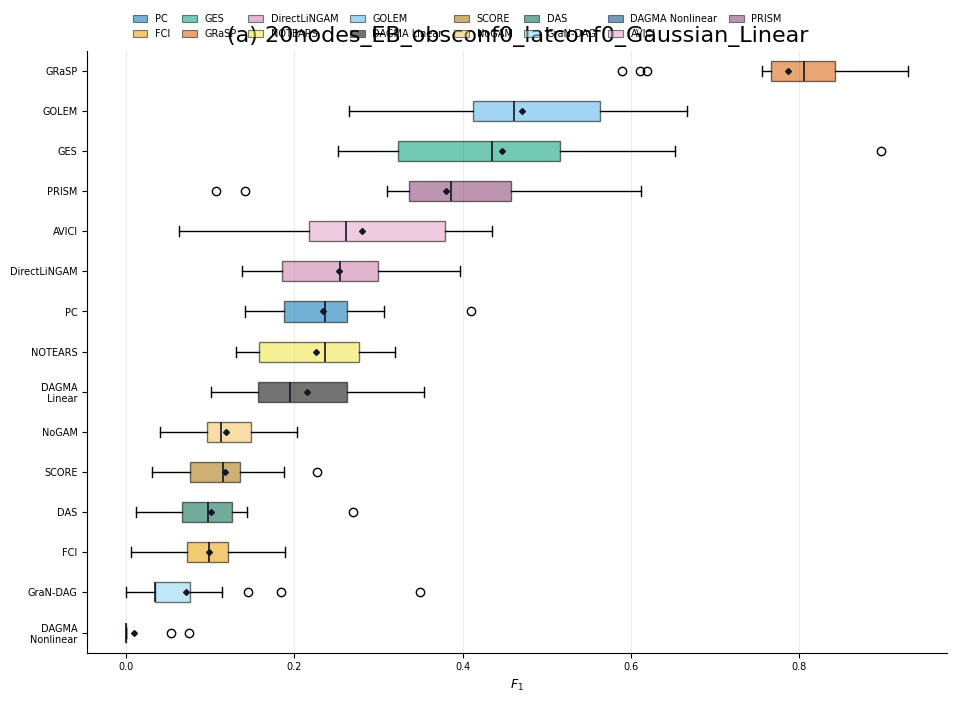

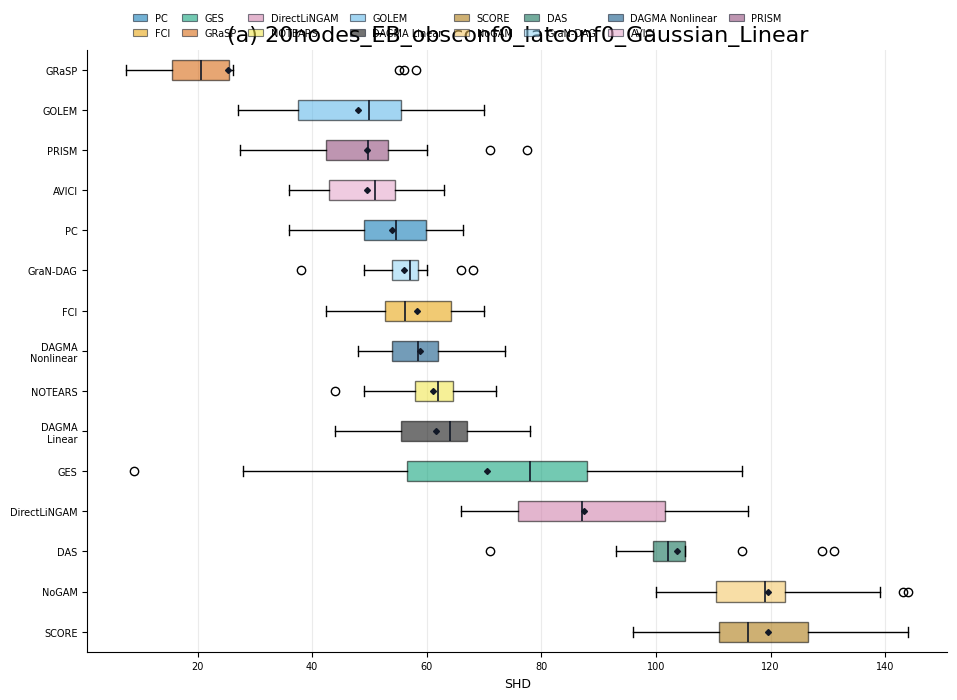

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.000000
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.151282
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.376443
9,19,GraNDAG,0.000000


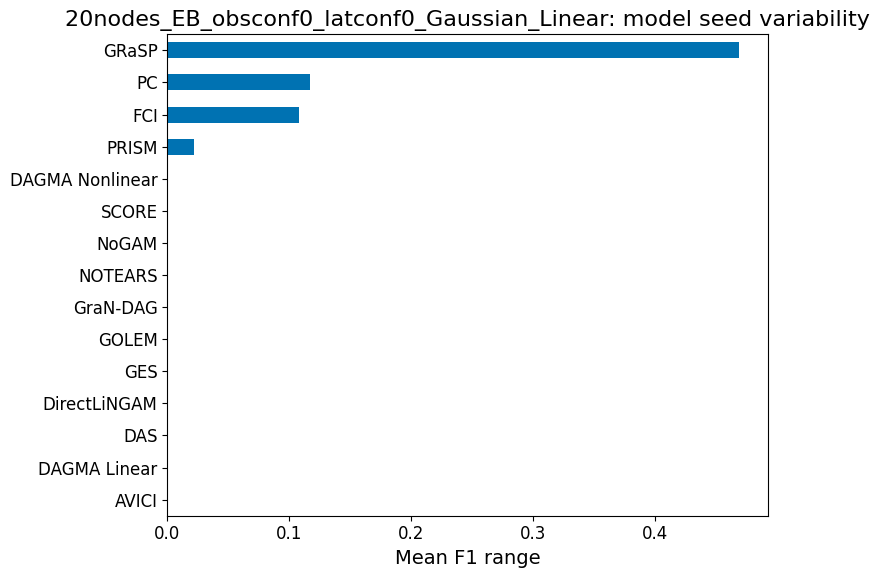

,model_seed,model,f1_range
0,0,AVICI,0.372283
1,0,DAGMA_Linear,0.252972
2,0,DAGMA_Nonlinear,0.074074
3,0,DAS,0.258605
4,0,DirectLiNGAM,0.259683
5,0,FCI,0.218182
6,0,GES,0.646304
7,0,GOLEM,0.401180
8,0,GRaSP,0.728261
9,0,GraNDAG,0.349206


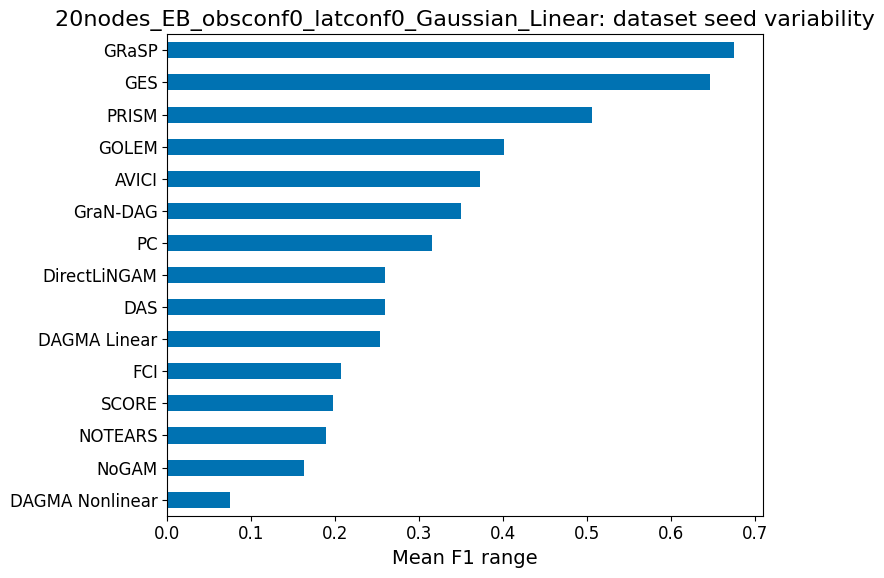

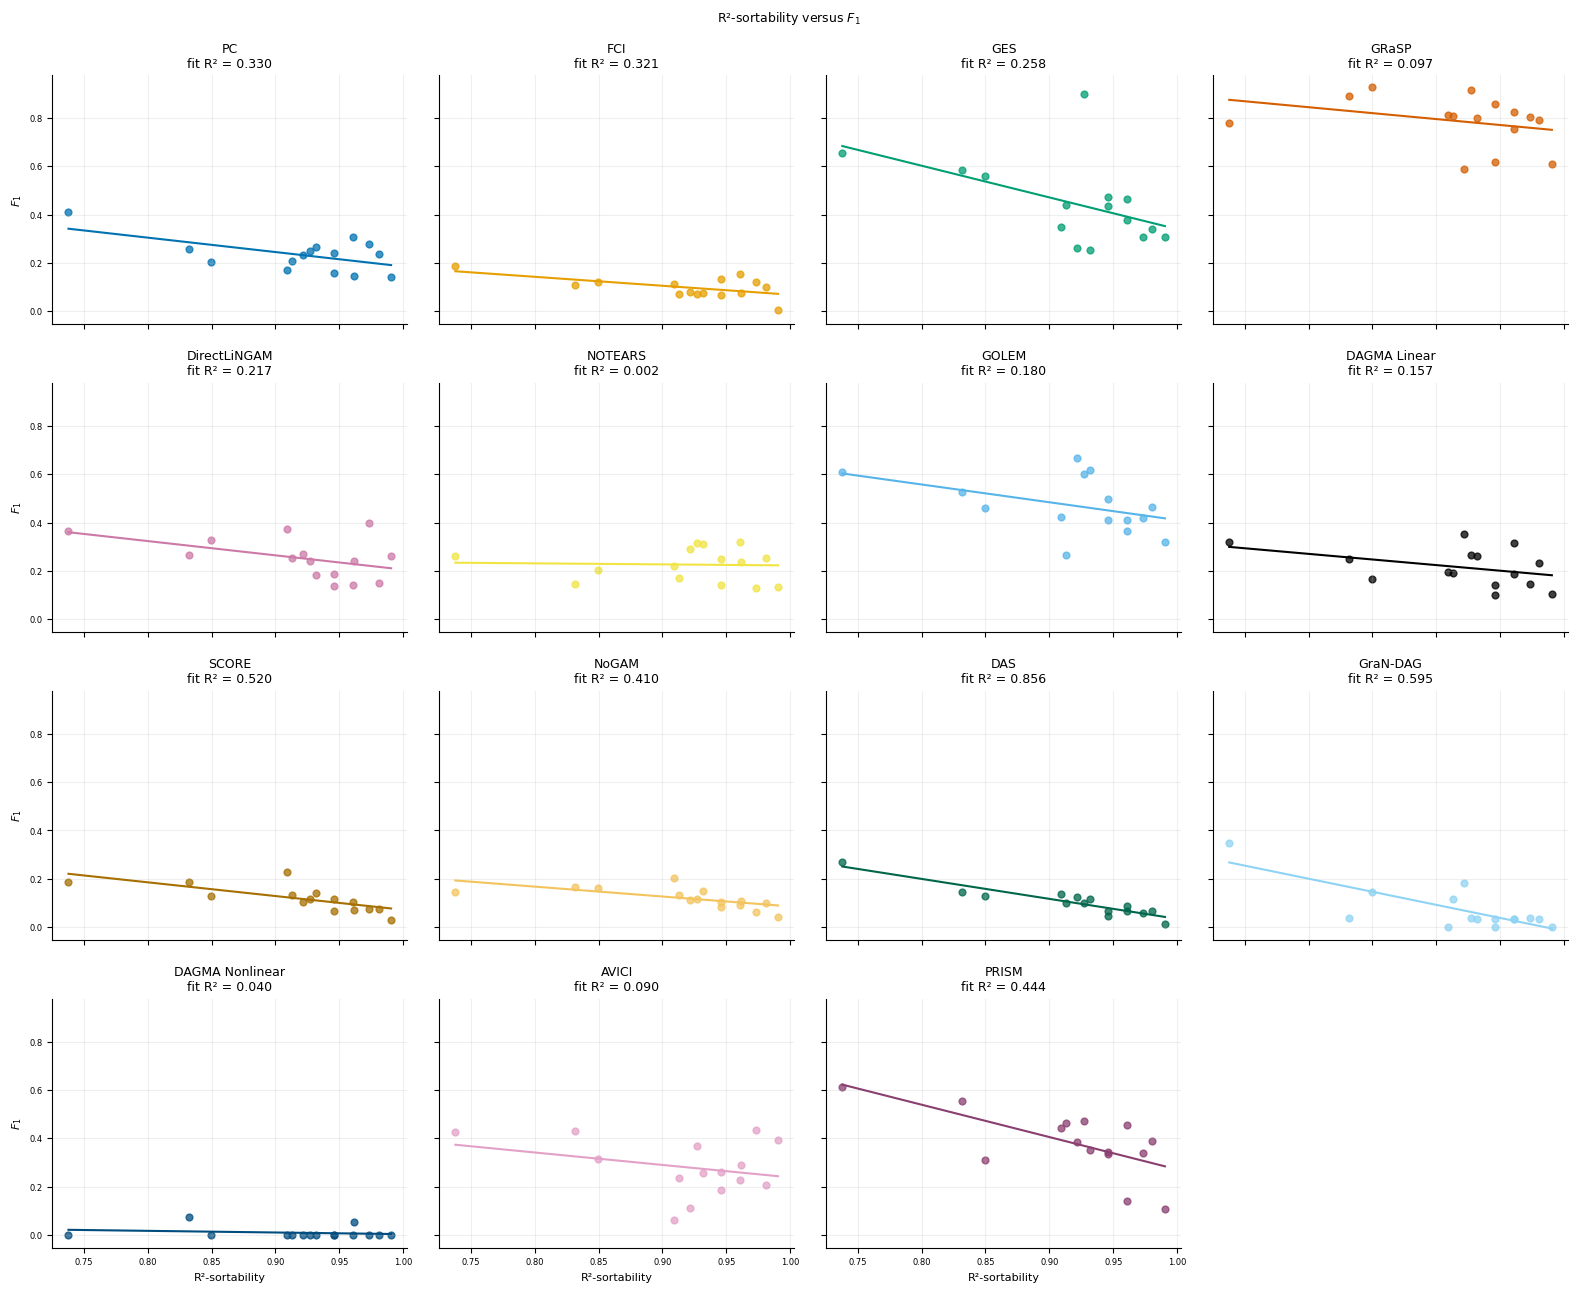

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,0.257143,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,0.260000,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,0.000000,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,0.115108,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,0.181818,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,FCI,0.075971,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GES,0.251656,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GOLEM,0.616822,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GRaSP,0.798983,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GraNDAG,0.033898,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.996226,0.973585,265,264,0,258,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982801,0.945946,407,400,0,385,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.996094,0.921875,256,255,0,236,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.983264,0.945607,239,235,0,226,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.971671,0.909348,353,343,0,321,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.979094,0.912892,287,281,0,262,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,1.000000,0.980695,259,259,0,254,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.965517,0.737931,145,140,0,107,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.968912,0.849741,193,187,0,164,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,-0.300560,0.090337,-0.516141,0.754319,2.763764e-01,-0.032143,9.094621e-01
1,DAGMA_Linear,15,-0.396121,0.156912,-0.465228,0.642380,1.438333e-01,-0.428571,1.109602e-01
2,DAGMA_Nonlinear,15,-0.200074,0.040030,-0.068416,0.071359,4.746464e-01,-0.120736,6.682023e-01
3,DAS,15,-0.925463,0.856482,-0.827441,0.861112,7.681026e-07,-0.925000,7.987462e-07
4,DirectLiNGAM,15,-0.466126,0.217274,-0.591247,0.796220,7.989257e-02,-0.453571,8.948590e-02
5,FCI,15,-0.566928,0.321407,-0.370561,0.438839,2.753785e-02,-0.278571,3.147095e-01
6,GES,15,-0.508375,0.258445,-1.313732,1.653806,5.298926e-02,-0.535714,3.956697e-02
7,GOLEM,15,-0.424236,0.179976,-0.736725,1.147136,1.150183e-01,-0.425000,1.142955e-01
8,GRaSP,15,-0.311871,0.097264,-0.492244,1.239145,2.578032e-01,-0.407143,1.320127e-01
9,GraNDAG,15,-0.771614,0.595388,-1.084357,1.067566,7.532590e-04,-0.574515,2.508718e-02


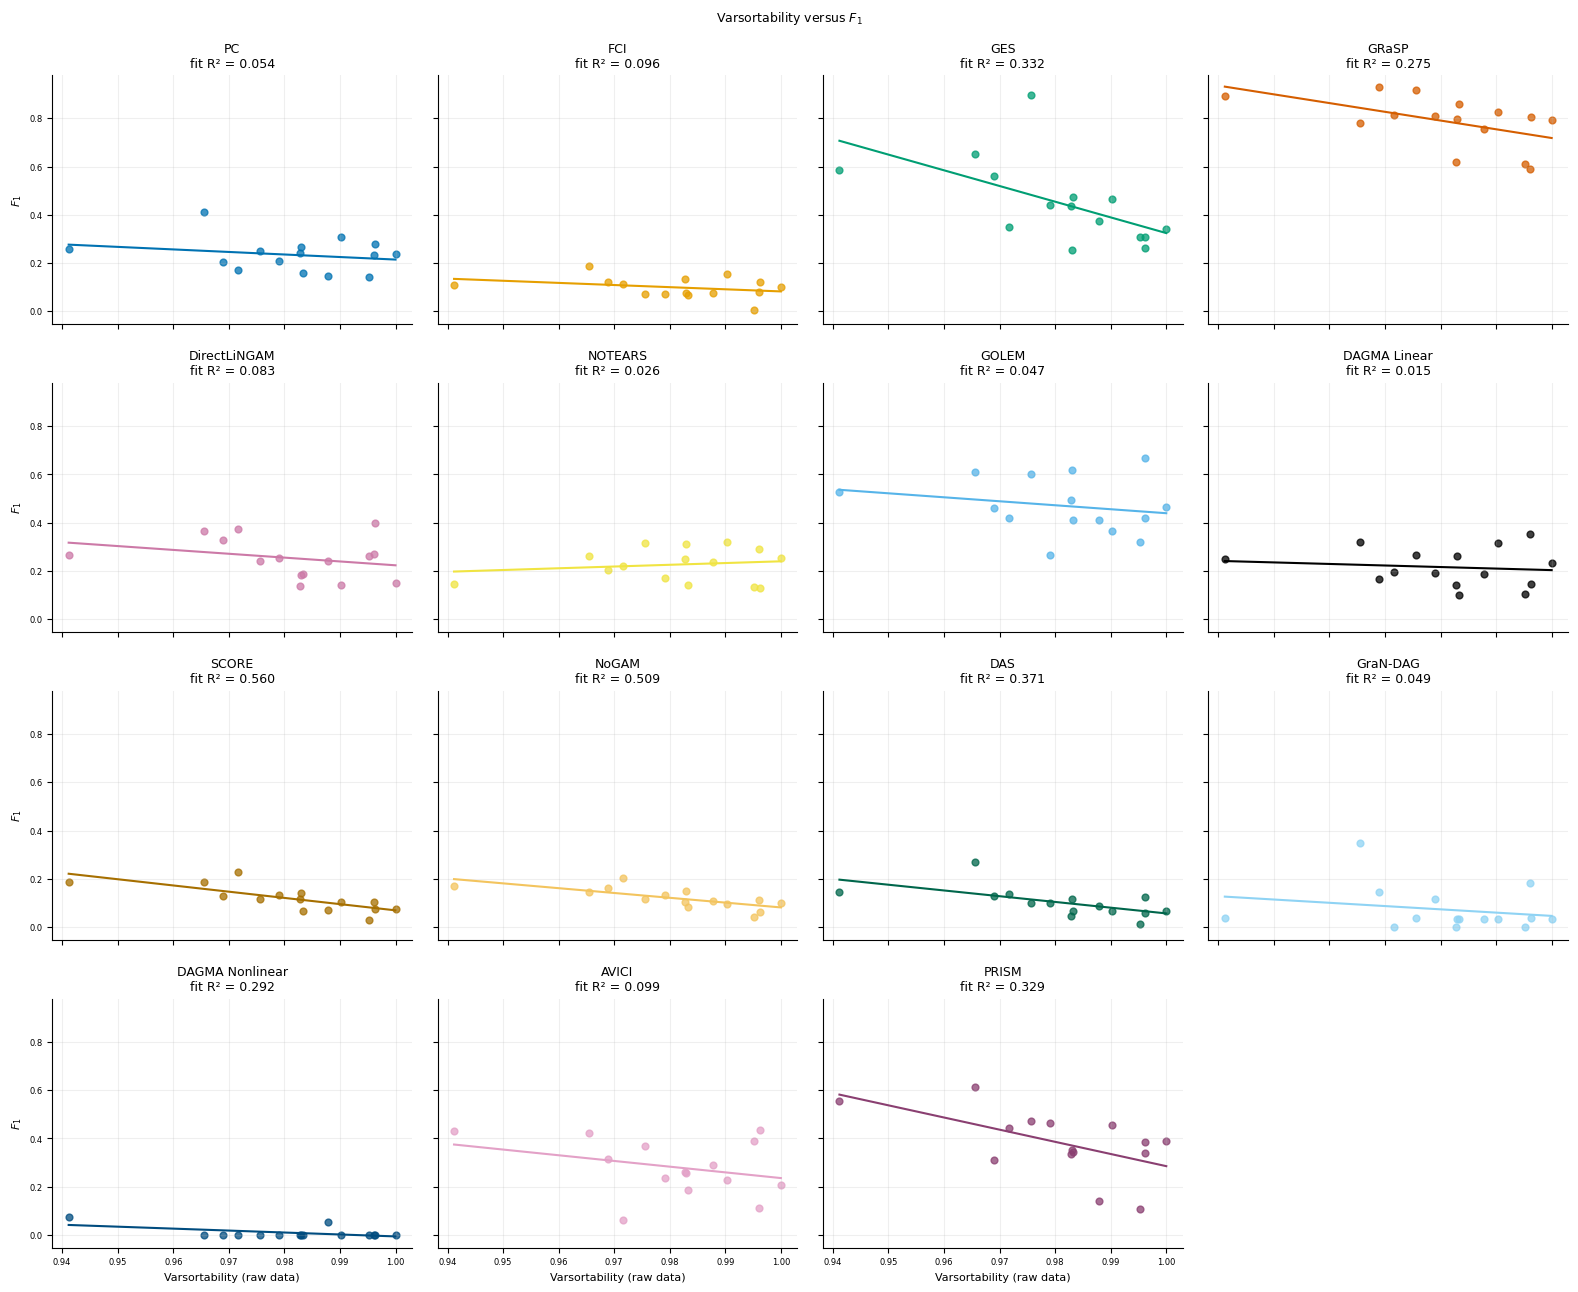

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,0.257143,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,0.260000,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,0.000000,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,0.115108,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,0.181818,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,FCI,0.075971,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GES,0.251656,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GOLEM,0.616822,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GRaSP,0.798983,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GraNDAG,0.033898,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.996226,0.973585,265,264,0,258,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982801,0.945946,407,400,0,385,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.996094,0.921875,256,255,0,236,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.983264,0.945607,239,235,0,226,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.971671,0.909348,353,343,0,321,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.979094,0.912892,287,281,0,262,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,1.000000,0.980695,259,259,0,254,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.965517,0.737931,145,140,0,107,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.968912,0.849741,193,187,0,164,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,-0.314994,0.099221,-2.366675,2.602102,0.252813,-0.253571,0.361816
1,DAGMA_Linear,15,-0.124487,0.015497,-0.639676,0.842555,0.658464,-0.150000,0.593630
2,DAGMA_Nonlinear,15,-0.540582,0.292229,-0.808776,0.802005,0.037472,-0.253546,0.361865
3,DAS,15,-0.608852,0.370701,-2.381710,2.437644,0.016000,-0.728571,0.002065
4,DirectLiNGAM,15,-0.287644,0.082739,-1.596318,1.819192,0.298539,-0.275000,0.321211
5,FCI,15,-0.309377,0.095714,-0.884746,0.966429,0.261832,-0.203571,0.466795
6,GES,15,-0.576162,0.331962,-6.514284,6.838095,0.024578,-0.692857,0.004190
7,GOLEM,15,-0.217483,0.047299,-1.652430,2.091504,0.436201,-0.235714,0.397703
8,GRaSP,15,-0.524854,0.275472,-3.624454,4.342910,0.044554,-0.510714,0.051725
9,GraNDAG,15,-0.221061,0.048868,-1.359204,1.404862,0.428500,-0.253146,0.362651


,model,mean,std,size
0,AVICI,0.456013,0.097466,15
1,DAGMA_Linear,0.176085,0.092673,15
2,DAGMA_Nonlinear,0.117738,0.063797,15
3,DAS,0.104180,0.053276,15
4,DirectLiNGAM,0.323469,0.096781,15
5,FCI,0.094382,0.068397,15
6,GES,0.439051,0.168780,15
7,GOLEM,0.128848,0.052325,15
8,GRaSP,0.786902,0.105380,15
9,GraNDAG,0.045684,0.027271,15


,model,mean,std,size
0,AVICI,56.933333,12.050291,15
1,DAGMA_Linear,60.666667,10.932695,15
2,DAGMA_Nonlinear,70.893333,12.097666,15
3,DAS,103.800000,12.370472,15
4,DirectLiNGAM,107.600000,18.961615,15
5,FCI,56.973333,9.151695,15
6,GES,79.666667,32.655489,15
7,GOLEM,84.133333,12.512089,15
8,GRaSP,25.360000,16.975983,15
9,GraNDAG,56.000000,6.233550,15


,model,mean,std,size
0,AVICI,0.473166,0.099755,15
1,DAGMA_Linear,0.221815,0.107973,15
2,DAGMA_Nonlinear,0.141300,0.073139,15
3,DAS,0.083282,0.043044,15
4,DirectLiNGAM,0.230843,0.074576,15
5,FCI,0.565612,0.261047,15
6,GES,0.353816,0.178387,15
7,GOLEM,0.119385,0.046658,15
8,GRaSP,0.785872,0.130427,15
9,GraNDAG,0.436825,0.310523,15


,model,mean,std,size
0,AVICI,0.451289,0.120968,15
1,DAGMA_Linear,0.147730,0.082901,15
2,DAGMA_Nonlinear,0.104849,0.061945,15
3,DAS,0.140035,0.071680,15
4,DirectLiNGAM,0.543443,0.138010,15
5,FCI,0.053216,0.041763,15
6,GES,0.601507,0.142907,15
7,GOLEM,0.142095,0.062716,15
8,GRaSP,0.798044,0.080069,15
9,GraNDAG,0.024421,0.014613,15


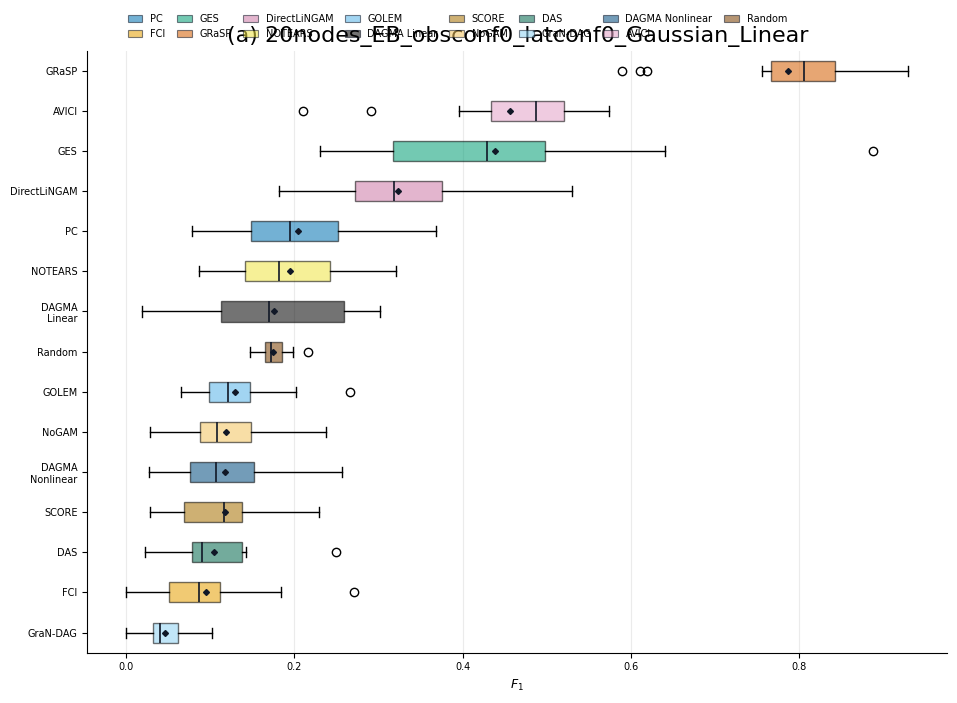

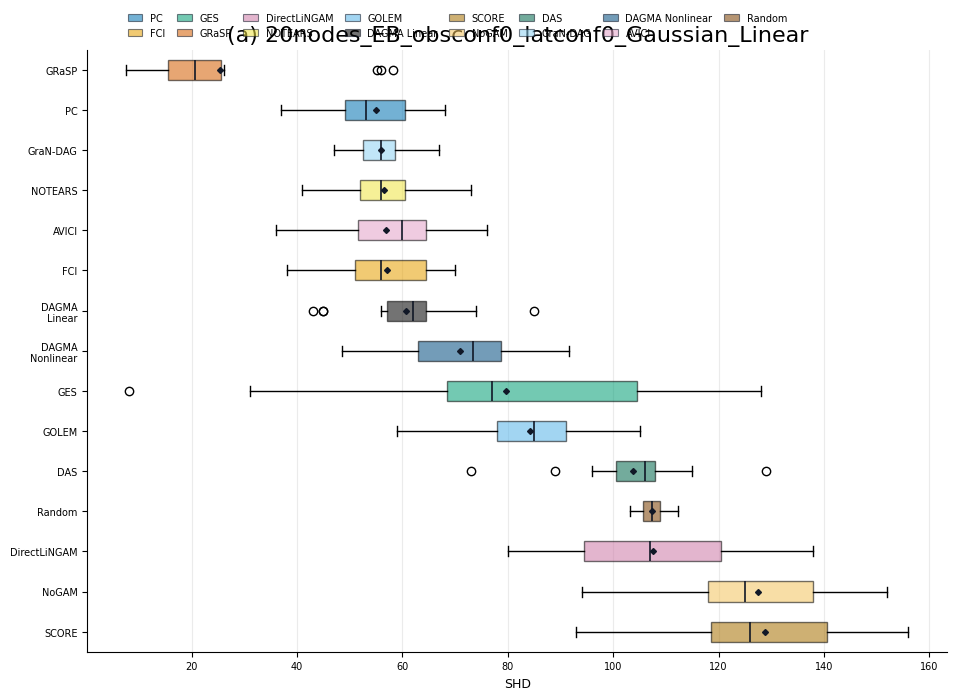

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.026077
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.000000
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.376443
9,19,GraNDAG,0.000000


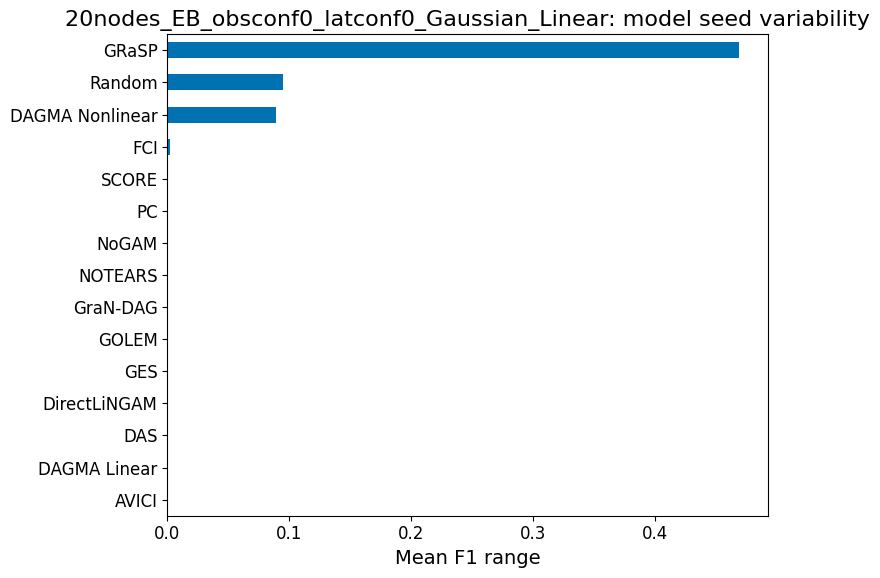

,model_seed,model,f1_range
0,0,AVICI,0.364186
1,0,DAGMA_Linear,0.283278
2,0,DAGMA_Nonlinear,0.295022
3,0,DAS,0.227654
4,0,DirectLiNGAM,0.348182
5,0,FCI,0.271186
6,0,GES,0.658522
7,0,GOLEM,0.202151
8,0,GRaSP,0.728261
9,0,GraNDAG,0.101695


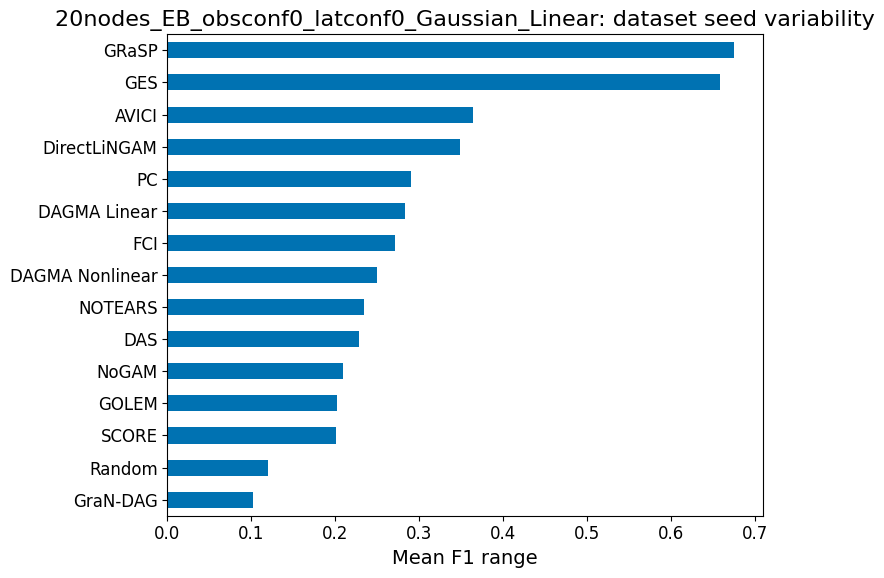

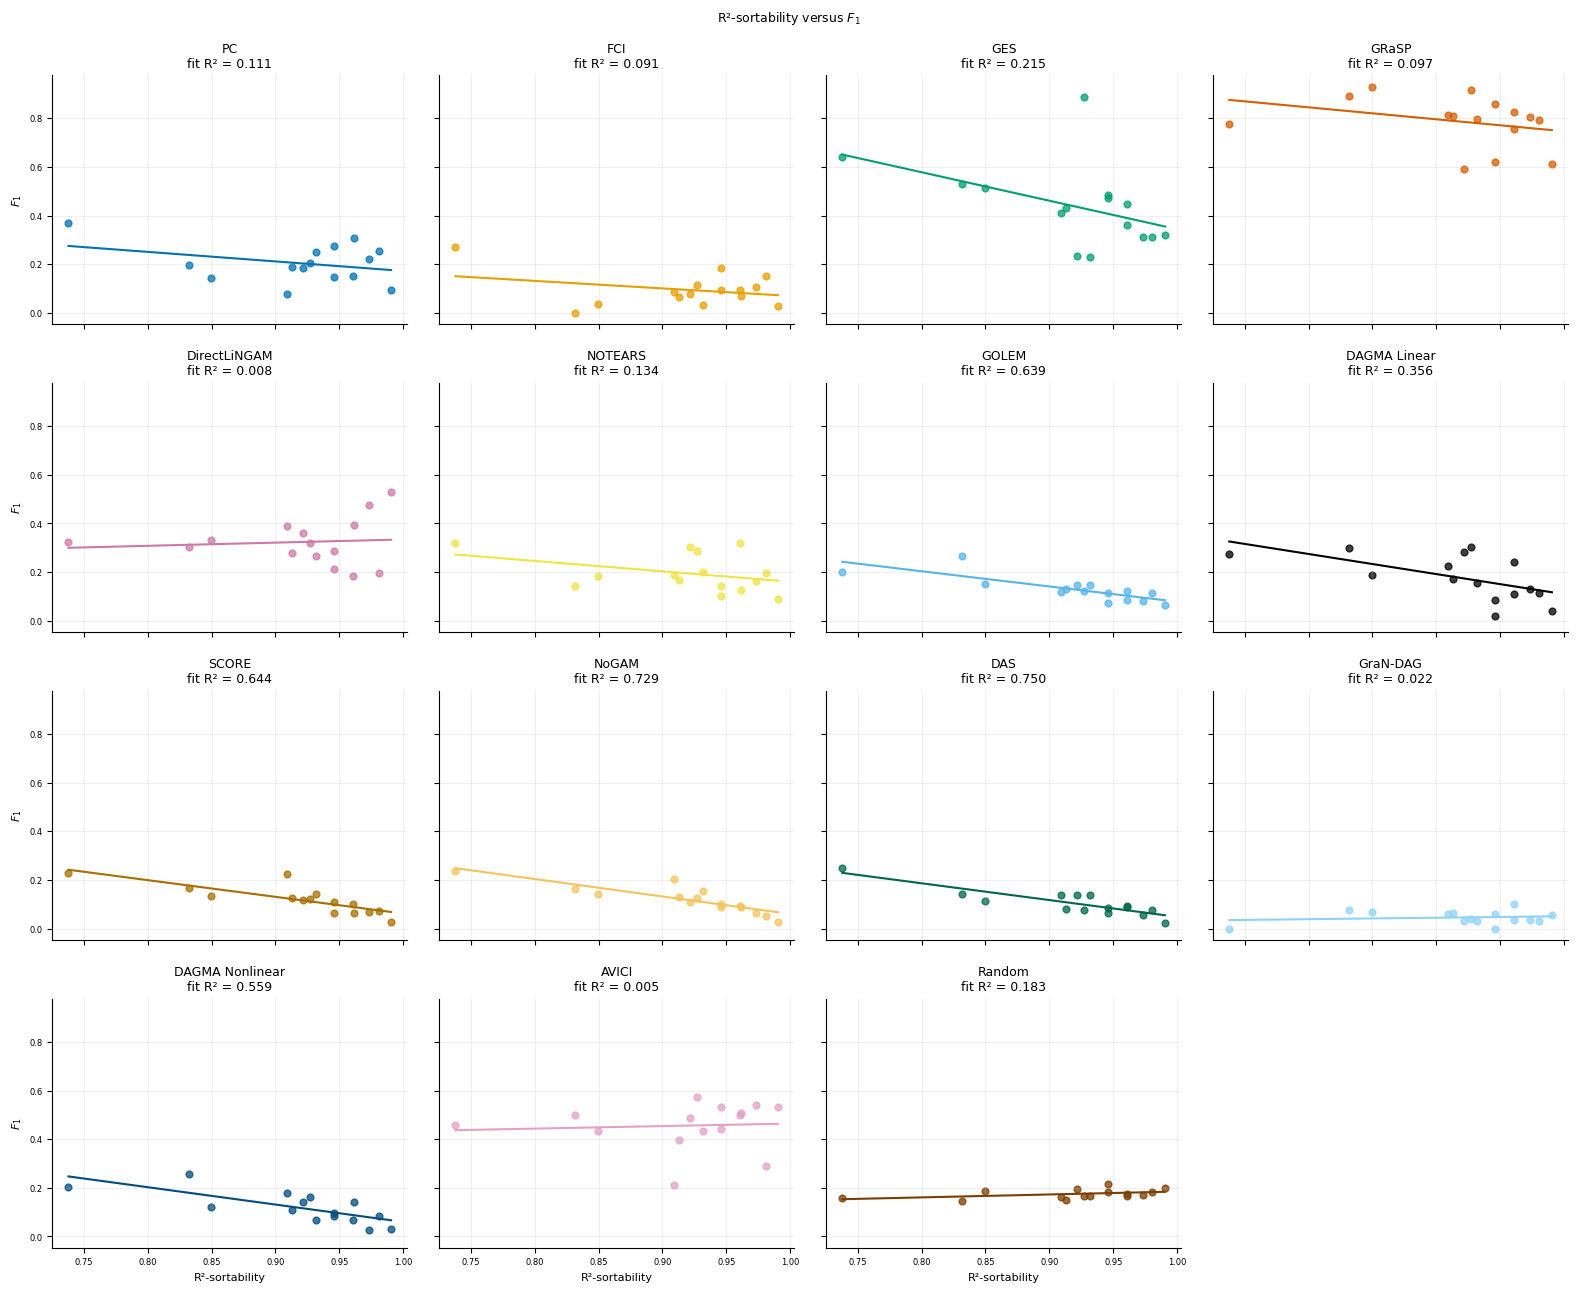

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,0.435484,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,0.155556,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,0.067972,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,0.136986,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,0.266010,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,FCI,0.032787,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GES,0.230366,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GOLEM,0.147059,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GRaSP,0.798983,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GraNDAG,0.032258,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.996226,0.973585,265,264,0,258,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982801,0.945946,407,400,0,385,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.996094,0.921875,256,255,0,236,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.983264,0.945607,239,235,0,226,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.971671,0.909348,353,343,0,321,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.979094,0.912892,287,281,0,262,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,1.000000,0.980695,259,259,0,254,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.965517,0.737931,145,140,0,107,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.968912,0.849741,193,187,0,164,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.070911,0.005028,0.103518,0.360908,0.801715,0.334227,2.233925e-01
1,DAGMA_Linear,15,-0.596272,0.355540,-0.827642,0.936471,0.018971,-0.678571,5.416550e-03
2,DAGMA_Nonlinear,15,-0.747556,0.558839,-0.714315,0.774006,0.001356,-0.771429,7.568751e-04
3,DAS,15,-0.865780,0.749575,-0.690846,0.738886,0.000030,-0.778571,6.273501e-04
4,DirectLiNGAM,15,0.090266,0.008148,0.130845,0.203257,0.749028,0.021429,9.395779e-01
5,FCI,15,-0.301902,0.091145,-0.309278,0.378527,0.274133,0.117963,6.754362e-01
6,GES,15,-0.463684,0.215003,-1.172165,1.515962,0.081698,-0.539286,3.802166e-02
7,GOLEM,15,-0.799155,0.638648,-0.626304,0.704258,0.000351,-0.835714,1.044469e-04
8,GRaSP,15,-0.311871,0.097264,-0.492244,1.239145,0.257803,-0.407143,1.320127e-01
9,GraNDAG,15,0.148595,0.022080,0.060694,-0.010078,0.597133,-0.114388,6.847975e-01


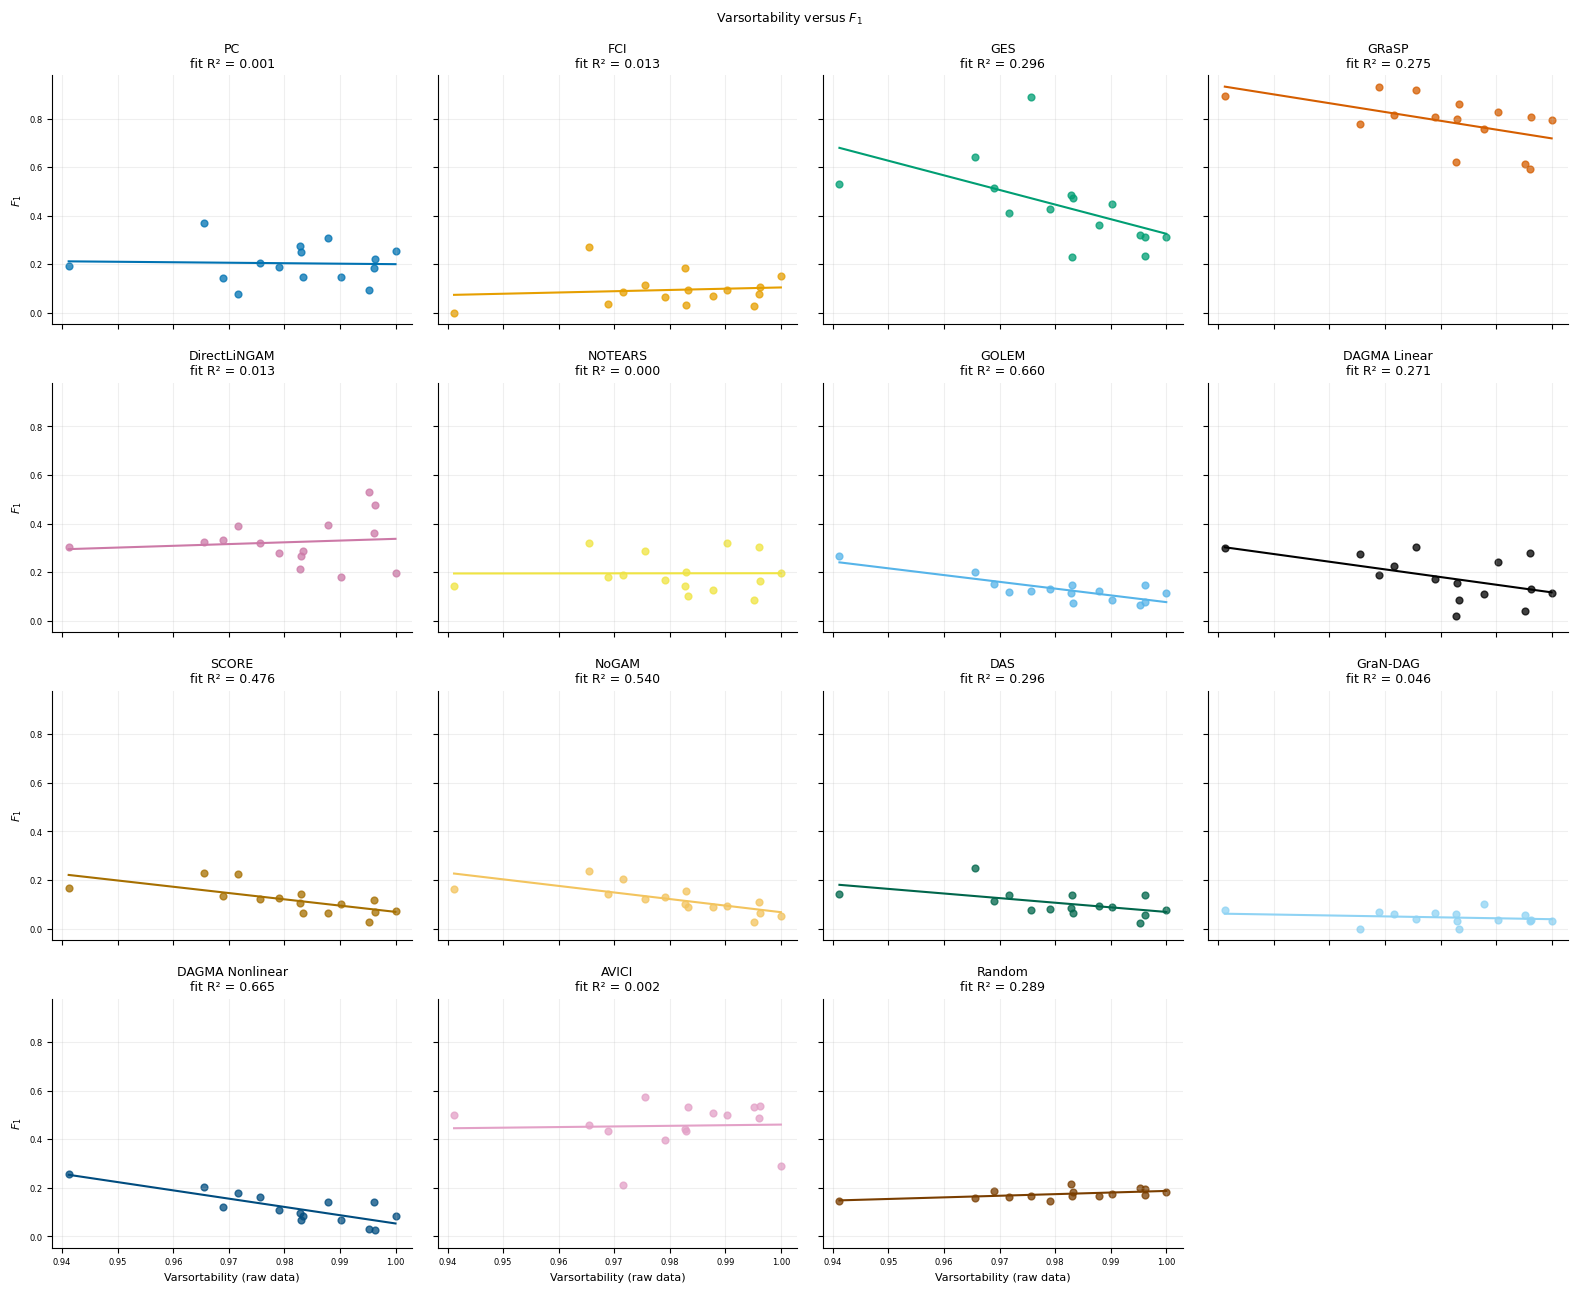

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,0.435484,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,0.155556,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,0.067972,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,0.136986,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,0.266010,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,FCI,0.032787,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GES,0.230366,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GOLEM,0.147059,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GRaSP,0.798983,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GraNDAG,0.032258,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982993,0.931973,294,289,0,274,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.996226,0.973585,265,264,0,258,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.982801,0.945946,407,400,0,385,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.996094,0.921875,256,255,0,236,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.983264,0.945607,239,235,0,226,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.971671,0.909348,353,343,0,321,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.979094,0.912892,287,281,0,262,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,1.000000,0.980695,259,259,0,254,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.965517,0.737931,145,140,0,107,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.968912,0.849741,193,187,0,164,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.039831,0.001587,0.254403,0.206414,0.887919,0.214477,0.442724
1,DAGMA_Linear,15,-0.520161,0.270568,-3.158897,3.275328,0.046847,-0.460714,0.083933
2,DAGMA_Nonlinear,15,-0.815515,0.665064,-3.409393,3.462746,0.000211,-0.735714,0.001770
3,DAS,15,-0.544069,0.296011,-1.899446,1.967756,0.036023,-0.592857,0.019846
4,DirectLiNGAM,15,0.113558,0.012895,0.720201,-0.383131,0.686976,0.035714,0.899447
5,FCI,15,0.115670,0.013379,0.518444,-0.414271,0.681436,0.146559,0.602222
6,GES,15,-0.544131,0.296078,-6.018229,6.343628,0.035998,-0.753571,0.001178
7,GOLEM,15,-0.812252,0.659753,-2.785125,2.861378,0.000234,-0.671429,0.006128
8,GRaSP,15,-0.524854,0.275472,-3.624454,4.342910,0.044554,-0.510714,0.051725
9,GraNDAG,15,-0.215119,0.046276,-0.384434,0.422858,0.441327,-0.369973,0.174671


In [3]:
for study, frame in [("tuned", complete)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf0_Gaussian_Linear')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,r2_sortability,15,-0.032143,9.094621e-01,estimated,1.000000
1,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.428571,1.109602e-01,estimated,0.887682
2,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.120736,6.682023e-01,estimated,1.000000
3,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,r2_sortability,15,-0.925000,7.987462e-07,estimated,0.000012
4,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,r2_sortability,15,-0.453571,8.948590e-02,estimated,0.805373
5,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,FCI,r2_sortability,15,-0.278571,3.147095e-01,estimated,1.000000
6,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GES,r2_sortability,15,-0.535714,3.956697e-02,estimated,0.395670
7,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GOLEM,r2_sortability,15,-0.425000,1.142955e-01,estimated,0.887682
8,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GRaSP,r2_sortability,15,-0.407143,1.320127e-01,estimated,0.887682
9,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GraNDAG,r2_sortability,15,-0.574515,2.508718e-02,estimated,0.275959
